# Batch effect diagnosis

**Question:** what drives the differences between the profiles? Is it biology (cell line, time point, treatment), or a technical effect (plate position, cell number, imaging time)?

A **batch effect** is a difference in the profiles that comes from *how* the wells were handled or measured, not from the biology. For example, assume that every other row of a plate received a little less medium. Then the DMSO wells in those rows look different from the other DMSO wells. A treatment in those rows then looks "active" only because of where it sits.

Each plate is one time point and one **batch**. The 3 replicate wells of a treatment always sit on the same plate. Treated wells can differ because of their treatment, so **we assess batch effects only on the DMSO wells**. All DMSO wells got the same treatment. Within one plate and cell line they should look alike, so any pattern among them is technical. The treated wells appear only in the biology overview (sections 4 and 5).

- **H0:** the DMSO wells of a plate and cell line differ only at random. No technical factor explains the differences.
- **H1:** a technical factor (plate position, cell number, imaging order) makes some DMSO wells differ more than others.

The notebook has two parts:

1. **Biology overview (sections 3–5):** UMAP maps of single cells and of all wells.
2. **Batch effects in the DMSO wells (sections 6–9):**
   - a UMAP of the DMSO wells only, colored by plate and by each technical factor (section 6).
   - the distance of each DMSO well from the typical DMSO well, drawn on the plate (section 7).
   - tests of each technical factor against this distance, and a test for gradients across the plate (section 8).
   - the share of features that follow cell number (section 9).

## Setup

Run with `_run.sbatch` (about 5 minutes, 30 GB of memory).

In [1]:
import os
import pathlib

n_threads = 32
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)
os.environ["NUMBA_NUM_THREADS"] = str(n_threads)

import mantispy as mt
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scanpy as sc
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy import stats
from sklearn.decomposition import PCA

In [2]:
# inputs: the QCed profiles of the preprocessing module, the all-cells well table (for cell counts),
# and the imaging records of each plate (time of every image)
preprocess_results = pathlib.Path("../2.preprocessing/results")
sc_profiles_path = (preprocess_results / "qced_norm_fs_Panc1_hPSC_sc-profiles.parquet").resolve(strict=True)
agg_profiles_path = (preprocess_results / "qced_agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)
all_cells_path = (preprocess_results / "agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)
imaging_dir = pathlib.Path("../../data/sc-profiles/PALS-screen-profiles-v2").resolve(strict=True)

# outputs
results_dir = pathlib.Path("results").resolve()
fig_dir = results_dir / "figures" / "01.batch-effects-diagnosis"
table_dir = results_dir / "tables" / "01.batch-effects-diagnosis"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

seed = 0
# cells sampled per well for the single-cell UMAP
cells_per_well = 100
# values beyond this many MADs are set to the limit, so a few extreme values cannot dominate
clip_limit = 20
# PCA keeps enough components to explain this share of the variance
explained_variance = 0.95
# neighbors per profile when building the UMAP
n_neighbors = 15
# a DMSO well is "unusual" when its distance from the DMSO centre is above the median + 3 MAD of its plate and cell line
unusual_mads = 3
# a feature "follows cell number" when |Spearman rho| with cell number is at least this, across the DMSO wells
strong_rho = 0.5

# fixed order and colors, the same in every notebook (checked for color-blind readers)
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
well_type_colors = {"control": "#bdbdbd", "compound": "#525252", "ligand": "#e34948"}
treatment_colors = {"DMSO": "#d9d9d9", "other treatment": "#8c8c8c", "TGFb1": "#e34948", "CBK600005": "#0d366b"}
background = "#e6e6e6"
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])

# the plate area where CL1 profiles are shifted at 1h and 4h: odd rows (A, C, ..., O) of columns 1-6
shifted_rows = list("ACEGIKMO")
shifted_columns = range(1, 7)
plate_rows = list("ABCDEFGHIJKLMNOP")

# figure style for print: figure sizes are the size on paper (7.2 in = full page width), text is 6-9 pt
sns.set_theme(style="ticks")
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6.5, "legend.title_fontsize": 7, "figure.titlesize": 9,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(60)


def save_fig(fig, name):
    """Save a figure as PNG (300 dpi) and PDF, then show it."""
    fig.savefig(fig_dir / f"{name}.png")
    fig.savefig(fig_dir / f"{name}.pdf")
    plt.show()

## 1. Load the profiles

We leave out the wells that fail well QC (fewer than 100 QC-passing cells, see `2.preprocessing`), together with their cells. We also drop single cells with a missing value, because PCA cannot use them.

**Pass if:** the well profiles have no missing values.

In [3]:
# mantispy returns an AnnData object: a matrix of features, and a table of metadata
sc_profiles = mt.io.read_profiles(sc_profiles_path, resolution="object")
agg_profiles = mt.io.read_profiles(agg_profiles_path, resolution="well")
print(f"single cells: {sc_profiles.n_obs:,} cells, {sc_profiles.n_vars:,} features")
print(f"wells: {agg_profiles.n_obs:,} wells, {agg_profiles.n_vars:,} features")

missing_per_cell = np.isnan(sc_profiles.X).sum(axis=1)
print(f"single cells with a missing value: {(missing_per_cell > 0).sum():,} ({100 * (missing_per_cell > 0).mean():.2f}%)")
print(f"missing values in the well profiles: {int(np.isnan(agg_profiles.X).sum())}")

failed_wells = agg_profiles.obs.loc[
    agg_profiles.obs["Metadata_well_qc"] == "fail",
    ["Metadata_time_point", "Metadata_cell_line", "Metadata_Well", "Metadata_Perturbation", "Metadata_CellCount", "Metadata_well_qc_reason"],
].reset_index(drop=True)
agg_profiles = agg_profiles[(agg_profiles.obs["Metadata_well_qc"] == "pass").to_numpy()].copy()
sc_profiles = sc_profiles[(missing_per_cell == 0) & (sc_profiles.obs["Metadata_well_qc"] == "pass").to_numpy()].copy()
print(f"kept: {agg_profiles.n_obs:,} wells, {sc_profiles.n_obs:,} cells")
failed_wells

single cells: 2,185,564 cells, 1,399 features
wells: 1,140 wells, 1,399 features


single cells with a missing value: 5,404 (0.25%)
missing values in the well profiles: 0


kept: 1,136 wells, 2,179,895 cells


,Metadata_time_point,Metadata_cell_line,Metadata_Well,Metadata_Perturbation,Metadata_CellCount,Metadata_well_qc_reason
0,24h,CL1,L04,DMSO,89,fewer than 100 cells
1,24h,CL1,N03,CBK175924_0.67,76,fewer than 100 cells
2,24h,CL1,N08,CBK175924_2.0,62,fewer than 100 cells
3,24h,CL1,N10,DMSO,39,fewer than 100 cells


**Result: PASS.**

- The data hold 2,185,564 cells and 1,140 wells, with 1,399 features.
- 5,404 cells (0.25%) have a missing value, and we drop them. The well profiles have no missing values.
- 4 wells fail well QC (24h plate, CL1, 39–89 QC-passing cells). We leave them out with their cells, so 1,136 wells and 2,179,895 cells remain.

## 2. Add the technical factors to each well

For each well, we add four technical factors:

- **cell number relative to DMSO:** log2(all cells in the well / median of the DMSO wells of the same plate and cell line). 0 = like DMSO, −1 = half as many cells. We count all cells before QC, because crowding depends on every cell in the well.
- **plate area:** whether the well sits in the odd rows of columns 1–6 (CL1 half). The plate map of section 7 points to this area.
- **wells to the plate edge:** 0 for the outer ring, up to 7 in the centre.
- **imaging time:** minutes after the microscope imaged the first well of the plate.

In [4]:
obs = agg_profiles.obs
# all cells per well (before QC), from the all-cells well table
all_counts = pl.read_parquet(all_cells_path, columns=["Metadata_Plate", "Metadata_Well", "Metadata_CellCount"]).with_columns(
    pl.col(pl.Categorical).cast(pl.String)
)
wells = (
    pl.from_pandas(obs[["Metadata_Plate", "Metadata_Well", "Metadata_Row", "Metadata_Column", "Metadata_cell_line", "Metadata_time_point",
                        "Metadata_treatment", "Metadata_Perturbation", "Metadata_well_type", "Metadata_Control_Type"]].reset_index(drop=True))
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
    .with_row_index("row")
    .join(all_counts.rename({"Metadata_CellCount": "n_cells_all"}), on=["Metadata_Plate", "Metadata_Well"], how="left", maintain_order="left")
    .with_columns(
        time_point=pl.col("Metadata_time_point"),
        cell_line=pl.col("Metadata_cell_line"),
        is_dmso=pl.col("Metadata_Control_Type") == "negcon",
        row_idx=pl.col("Metadata_Row").map_elements(plate_rows.index, return_dtype=pl.Int64),
        col_idx=pl.col("Metadata_Column").cast(pl.Int64) - 1,
    )
    .with_columns(
        log2_cells=(pl.col("n_cells_all") / pl.col("n_cells_all").filter(pl.col("is_dmso")).median().over("Metadata_Plate", "cell_line")).log(2),
        shifted_area=(pl.col("cell_line") == "CL1") & pl.col("Metadata_Row").is_in(shifted_rows) & (pl.col("col_idx") + 1).is_in(list(shifted_columns)),
        wells_to_edge=pl.min_horizontal(pl.col("row_idx"), 15 - pl.col("row_idx"), pl.col("col_idx"), 23 - pl.col("col_idx")),
    )
)

# imaging time: the first image of each well, in minutes after the plate started
image_times = []
for plate_dir in sorted(p for p in imaging_dir.iterdir() if p.is_dir()):
    coords = pl.read_ndjson(plate_dir / "input" / plate_dir.name / "coords.jsonl")
    image_times.append(
        coords.group_by("well").agg(minutes_after_start=pl.col("ts").min() / 60)
        .with_columns(time_point=pl.lit(plate_dir.name.split("_")[3]))
        .rename({"well": "Metadata_Well"})
    )
wells = wells.join(pl.concat(image_times), on=["time_point", "Metadata_Well"], how="left", maintain_order="left")
assert wells["n_cells_all"].null_count() == 0 and wells["minutes_after_start"].null_count() == 0
wells.group_by("time_point", "cell_line").agg(
    wells=pl.len(), dmso_wells=pl.col("is_dmso").sum(), wells_in_shifted_area=pl.col("shifted_area").sum(),
    imaging_minutes=pl.col("minutes_after_start").max().round(0),
).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")

time_point,cell_line,wells,dmso_wells,wells_in_shifted_area,imaging_minutes
str,str,u32,u32,u32,f64
"""1h""","""CL1""",190,127,47,227.0
"""1h""","""CL2""",190,127,0,221.0
"""4h""","""CL1""",190,127,47,226.0
"""4h""","""CL2""",190,127,0,219.0
"""24h""","""CL1""",186,125,47,229.0
"""24h""","""CL2""",190,127,0,222.0


## 3. PCA and UMAP

A **UMAP** places similar profiles close together on a 2D map. We make two maps:

- **Single cells:** a random sample of 100 cells per well, so every well counts equally. All 2 million cells would take hours, and the dots would cover each other.
- **Wells:** the well profiles (median of the QC-passing cells of each well). The median removes the variation between single cells, so differences between wells show more clearly.

The steps are:

1. Clip values beyond ±20 MADs.
2. Keep the principal components that explain 95% of the variance (PCA).
3. Connect each profile to its 15 nearest neighbors, and draw the map.

In [5]:
sc_sample = mt.pp.downsample(sc_profiles, n_per_group=cells_per_well, by=("Metadata_Plate", "Metadata_Well"), seed=seed)
del sc_profiles


def embed(adata, name):
    """Clip extreme values, run PCA (95% of the variance), and compute the UMAP of one AnnData object."""
    clipped = np.abs(adata.X) > clip_limit
    print(f"{name}: {100 * clipped.mean():.3f}% of values clipped to ±{clip_limit}, in {clipped.any(axis=0).sum()} features")
    adata.X = np.clip(adata.X, -clip_limit, clip_limit)
    pca = PCA(n_components=explained_variance, svd_solver="full", random_state=seed)
    adata.obsm["X_pca"] = pca.fit_transform(adata.X)
    print(f"{name}: {pca.n_components_} principal components explain {100 * pca.explained_variance_ratio_.sum():.1f}% of the variance")
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, use_rep="X_pca", random_state=seed)
    sc.tl.umap(adata, random_state=seed)


print(f"{sc_sample.n_obs:,} cells sampled from {sc_sample.obs[['Metadata_Plate', 'Metadata_Well']].drop_duplicates().shape[0]:,} wells")
embed(sc_sample, "single cells")
embed(agg_profiles, "wells")

113,600 cells sampled from 1,136 wells
single cells: 0.078% of values clipped to ±20, in 723 features


single cells: 397 principal components explain 95.0% of the variance


wells: 0.003% of values clipped to ±20, in 14 features


wells: 16 principal components explain 95.2% of the variance


**Result:**

- 0.078% of the single-cell values and 0.003% of the well values are clipped.
- Single cells need 397 principal components to explain 95% of the variance. Wells need only 16, because the median of each well removes most of the variation between single cells.

## 4. What separates the single cells?

Each dot is one cell.

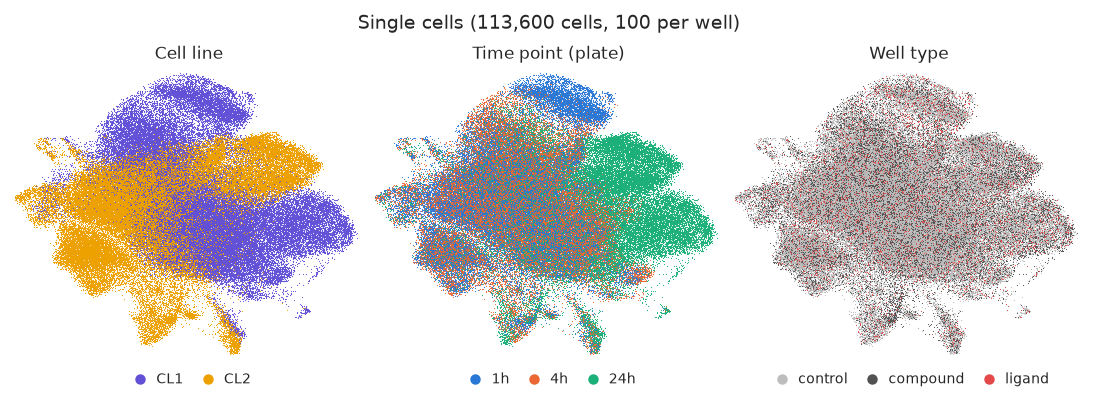

In [6]:
def umap_panel(ax, xy, groups, colors, title, size, order=None):
    """Scatter one UMAP colored by a category; categories are drawn in the given order (last on top)."""
    groups = np.asarray(groups)
    for name in order or colors:
        chosen = groups == name
        ax.scatter(*xy[chosen].T, s=size, color=colors[name], linewidths=0, rasterized=True, label=name)
    ax.set(title=title, xticks=[], yticks=[])
    ax.spines[["left", "bottom"]].set_visible(False)


cell_xy = sc_sample.obsm["X_umap"]
cell_obs = sc_sample.obs.astype({"Metadata_cell_line": str, "Metadata_time_point": str, "Metadata_well_type": str})
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6), layout="constrained")
# shuffle the drawing order, so no group covers another only because it is drawn last
shuffle = np.random.default_rng(seed).permutation(sc_sample.n_obs)
for ax, column, colors, title in [
    (axes[0], "Metadata_cell_line", line_colors, "Cell line"),
    (axes[1], "Metadata_time_point", plate_colors, "Time point (plate)"),
    (axes[2], "Metadata_well_type", well_type_colors, "Well type"),
]:
    groups = cell_obs[column].to_numpy()[shuffle]
    xy = cell_xy[shuffle]
    for k in range(0, len(xy), 5000):
        for name, color in colors.items():
            chosen = groups[k : k + 5000] == name
            ax.scatter(*xy[k : k + 5000][chosen].T, s=0.3, color=color, linewidths=0, rasterized=True)
    # a few far-out cells would shrink the map; show the range of 99.8% of the cells
    low, high = np.percentile(cell_xy, [0.1, 99.9], axis=0)
    margin = 0.03 * (high - low)
    ax.set(title=title, xticks=[], yticks=[], xlim=(low[0] - margin[0], high[0] + margin[0]), ylim=(low[1] - margin[1], high[1] + margin[1]))
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, markersize=4, label=n) for n, c in colors.items()],
              loc="upper center", bbox_to_anchor=(0.5, -0.02), ncols=3, handletextpad=0.2, columnspacing=0.8)
fig.suptitle(f"Single cells ({sc_sample.n_obs:,} cells, {cells_per_well} per well)")
save_fig(fig, "01_umap_single-cells")

**Result:** cells group first by cell line, then by time point. Cells at 24h separate from cells at 1h and 4h, which overlap. Control, compound and ligand cells mix everywhere. So the treatment effects are small next to the differences between single cells.

## 5. What separates the wells?

Each dot is one well, DMSO or treated. This map shows the biology (cell line, time point, treatment). Section 6 looks at the technical factors, on the DMSO wells only.

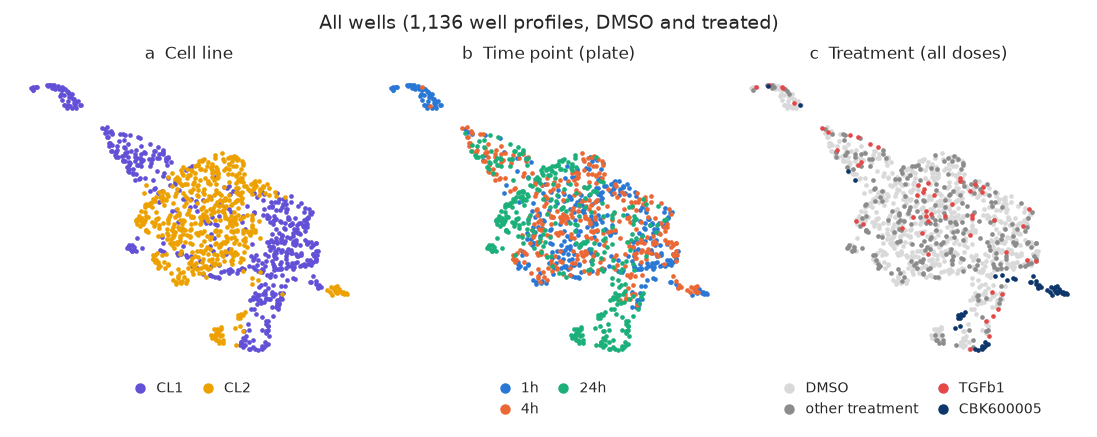

In [7]:
well_xy = agg_profiles.obsm["X_umap"]
treatment_group = np.where(
    wells["is_dmso"].to_numpy(), "DMSO",
    np.where(wells["Metadata_treatment"].is_in(["TGFb1", "CBK600005"]).to_numpy(), wells["Metadata_treatment"].to_numpy(), "other treatment"),
)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.8), layout="constrained")
size = 5
umap_panel(axes[0], well_xy, wells["cell_line"], line_colors, "a  Cell line", size)
umap_panel(axes[1], well_xy, wells["time_point"], plate_colors, "b  Time point (plate)", size)
umap_panel(axes[2], well_xy, treatment_group, treatment_colors, "c  Treatment (all doses)", size)
for ax, colors in zip(axes, [line_colors, plate_colors, treatment_colors]):
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, markersize=4, label=n) for n, c in colors.items()],
              loc="upper center", bbox_to_anchor=(0.5, -0.02), ncols=2, handletextpad=0.2, columnspacing=0.8)
fig.suptitle(f"All wells ({agg_profiles.n_obs:,} well profiles, DMSO and treated)")
save_fig(fig, "02_umap_wells")

**Result:**

- Each cell line is normalized to its own DMSO wells, so the two lines overlap in most of the map. The 24h wells spread into arms (b).
- CBK600005 forms its own groups at the edge of the map (c). TGFβ1 and the other treatments mostly mix with DMSO.
- A separate island sits at the top left. It holds DMSO wells and treated wells, so it is not a treatment effect. Section 6 shows what it is.

## 6. Batch effects: UMAP of the DMSO wells

From here on, we use **only the DMSO wells**. We repeat the PCA (95% of the variance) and the UMAP on the DMSO wells alone, so treatment effects cannot shape the map. Then we color the map by the batch (plate), the cell line, and each technical factor of section 2. In panel c, the DMSO wells in the odd rows of columns 1–6 (CL1) are colored by plate. All other DMSO wells are grey.

**Pass if:** the DMSO wells of each plate and cell line form one even cloud, with no group that follows a technical factor.

DMSO wells: 0.000% of values clipped to ±20, in 0 features
DMSO wells: 12 principal components explain 95.1% of the variance


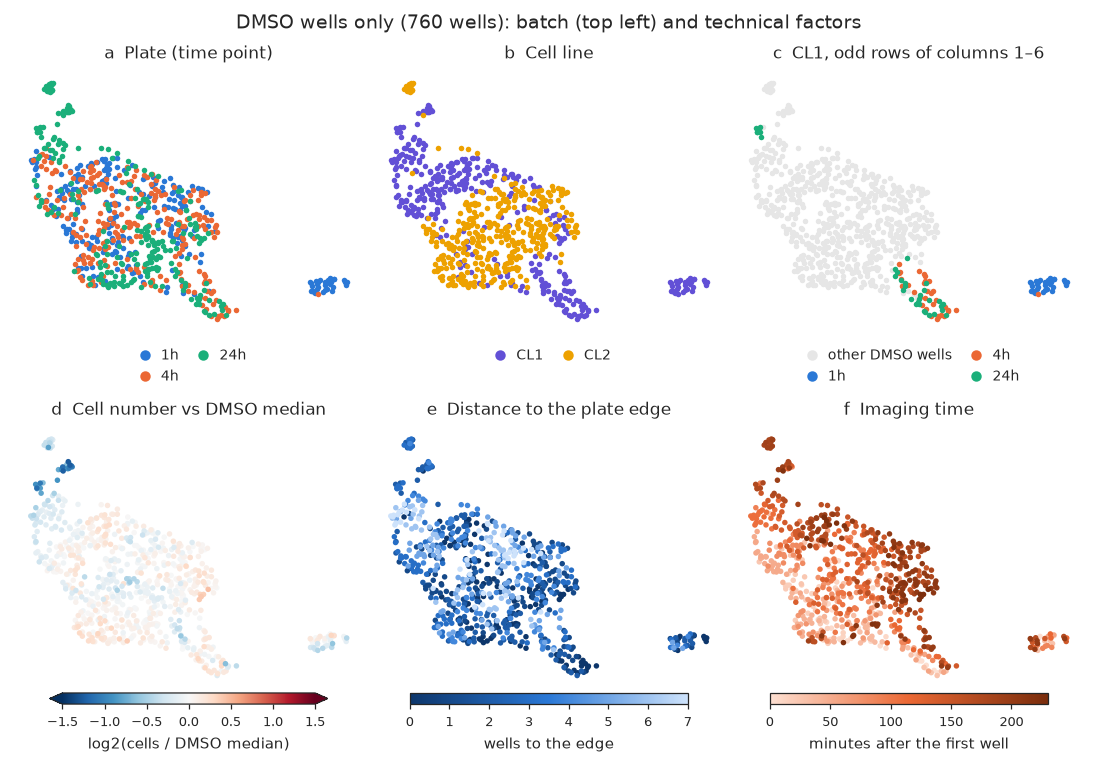

In [8]:
dmso_rows = wells.filter(pl.col("is_dmso"))["row"].to_numpy()
dmso_adata = agg_profiles[dmso_rows].copy()
embed(dmso_adata, "DMSO wells")
dmso = wells.filter(pl.col("is_dmso"))
dmso_xy = dmso_adata.obsm["X_umap"]
dmso_area = np.where(dmso["shifted_area"].to_numpy(), dmso["time_point"].to_numpy(), "other DMSO wells")
oranges = LinearSegmentedColormap.from_list("oranges", ["#fde0d2", "#eb6834", "#7a2d0c"])

fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.0), layout="constrained")
size = 7
umap_panel(axes[0, 0], dmso_xy, dmso["time_point"], plate_colors, "a  Plate (time point)", size)
umap_panel(axes[0, 1], dmso_xy, dmso["cell_line"], line_colors, "b  Cell line", size)
umap_panel(axes[0, 2], dmso_xy, dmso_area, {"other DMSO wells": background, **plate_colors}, "c  CL1, odd rows of columns 1–6", size)
for ax, colors in [(axes[0, 0], plate_colors), (axes[0, 1], line_colors), (axes[0, 2], {"other DMSO wells": background, **plate_colors})]:
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, markersize=4, label=n) for n, c in colors.items()],
              loc="upper center", bbox_to_anchor=(0.5, -0.02), ncols=2, handletextpad=0.2, columnspacing=0.8)
for ax, values, cmap, norm, title, label in [
    (axes[1, 0], dmso["log2_cells"].to_numpy(), plt.get_cmap("RdBu_r"), TwoSlopeNorm(0, -1.5, 1.5), "d  Cell number vs DMSO median", "log2(cells / DMSO median)"),
    (axes[1, 1], dmso["wells_to_edge"].to_numpy(), blues.reversed(), Normalize(0, 7), "e  Distance to the plate edge", "wells to the edge"),
    (axes[1, 2], dmso["minutes_after_start"].to_numpy(), oranges, Normalize(0, 230), "f  Imaging time", "minutes after the first well"),
]:
    # draw the most extreme wells last, so they are not covered
    order = np.argsort(np.abs(norm(values) - 0.5)) if isinstance(norm, TwoSlopeNorm) else np.argsort(values)
    points = ax.scatter(*dmso_xy[order].T, c=values[order], cmap=cmap, norm=norm, s=size, linewidths=0, rasterized=True)
    ax.set(title=title, xticks=[], yticks=[])
    ax.spines[["left", "bottom"]].set_visible(False)
    fig.colorbar(points, ax=ax, location="bottom", shrink=0.8, aspect=25, pad=0.02, label=label, extend="both" if ax is axes[1, 0] else "neither")
fig.suptitle(f"DMSO wells only ({dmso_adata.n_obs:,} wells): batch (top left) and technical factors")
save_fig(fig, "02b_umap_dmso-wells")

In [9]:
# how far each group of DMSO wells sits from the centre of the DMSO map, by plate, cell line and plate area
centre = np.median(dmso_xy, axis=0)
dmso = dmso.with_columns(umap_distance_from_centre=pl.Series(np.linalg.norm(dmso_xy - centre, axis=1)))
dmso.group_by("time_point", "cell_line", "shifted_area").agg(
    dmso_wells=pl.len(), median_umap_distance_from_centre=pl.col("umap_distance_from_centre").median().round(1),
).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line", "shifted_area")

time_point,cell_line,shifted_area,dmso_wells,median_umap_distance_from_centre
str,str,bool,u32,f32
"""1h""","""CL1""",false,94,4.1
"""1h""","""CL1""",true,33,11.9
"""1h""","""CL2""",false,127,2.9
"""4h""","""CL1""",false,94,3.8
"""4h""","""CL1""",true,33,6.5
"""4h""","""CL2""",false,127,2.9
"""24h""","""CL1""",false,92,4.4
"""24h""","""CL1""",true,33,6.7
"""24h""","""CL2""",false,127,2.9


**Result: FAIL. The DMSO wells form groups that follow technical factors.**

- **Plate (a).** The DMSO wells of the 3 plates mix. Each plate was normalized to its own DMSO cells, so the batches show no overall shift.
- **Plate area (c).** The CL1 DMSO wells in the odd rows of columns 1–6 at 1h form their own island (right). They lie 2.9 times further from the map centre than the other CL1 DMSO wells of that plate. The medians are 11.9 vs 4.1 UMAP units. At 4h and 24h, the same wells sit at the edge of the main cloud (6.5 vs 3.8, and 6.7 vs 4.4).
- **Cell number (d).** The small groups at the top left are 24h DMSO wells with few cells (blue).
- **Imaging time (f).** Imaging time runs as a smooth gradient across the main cloud, from early rows (light) to late rows (dark). Section 8b tests this gradient.
- **Cell line (b).** The two cell lines still separate partly, as expected. They differ in biology, even after we normalized each line to its own DMSO wells.

## 7. Where on the plate do the DMSO wells differ?

The UMAP distorts distances, so from here on we measure distances directly.

1. **Rescale.** For each plate and cell line, we rescale every feature to the spread between its DMSO wells. We subtract the median DMSO well, and divide by 1.4826 × MAD of the DMSO wells. A value of 3 then means "3 times the normal well-to-well variation of DMSO".
2. **Distance from DMSO.** The distance of a well is the Euclidean length of its rescaled profile. 0 is the typical DMSO well. Notebook 03 uses the same distance.
3. **Unusual DMSO well.** A DMSO well is unusual when its distance is above the median + 3 MAD of the DMSO wells of its plate and cell line.

The maps show only the DMSO wells. Treated wells are grey.

In [10]:
raw = np.clip(agg_profiles.X.astype(np.float64), -clip_limit, clip_limit)
profiles = np.empty_like(raw)
for (plate, line), grp in wells.group_by("Metadata_Plate", "cell_line"):
    rows = grp["row"].to_numpy()
    dmso = raw[grp.filter(pl.col("is_dmso"))["row"].to_numpy()]
    centre = np.median(dmso, axis=0)
    spread = 1.4826 * np.median(np.abs(dmso - centre), axis=0)
    # a few features hardly vary between DMSO wells; a floor stops them from blowing up
    spread = np.maximum(spread, np.quantile(spread[spread > 0], 0.01))
    profiles[rows] = (raw[rows] - centre) / spread
profiles = np.clip(profiles, -clip_limit, clip_limit)

wells = wells.with_columns(distance=pl.Series(np.linalg.norm(profiles, axis=1))).with_columns(
    distance_limit=(
        pl.col("distance").filter(pl.col("is_dmso")).median()
        + unusual_mads * 1.4826 * (pl.col("distance").filter(pl.col("is_dmso")) - pl.col("distance").filter(pl.col("is_dmso")).median()).abs().median()
    ).over("Metadata_Plate", "cell_line")
).with_columns(unusual_dmso=pl.col("is_dmso") & (pl.col("distance") > pl.col("distance_limit")))

dmso_health = (
    wells.filter(pl.col("is_dmso"))
    .group_by("time_point", "cell_line")
    .agg(
        dmso_wells=pl.len(),
        median_distance=pl.col("distance").median().round(1),
        distance_limit=pl.col("distance_limit").first().round(1),
        unusual_wells=pl.col("unusual_dmso").sum(),
        unusual_in_shifted_area=(pl.col("unusual_dmso") & pl.col("shifted_area")).sum(),
        median_cells_unusual=pl.col("n_cells_all").filter(pl.col("unusual_dmso")).median(),
        median_cells_other=pl.col("n_cells_all").filter(~pl.col("unusual_dmso")).median(),
    )
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)
dmso_health.write_csv(table_dir / "dmso_unusual-wells.csv")
dmso_health

time_point,cell_line,dmso_wells,median_distance,distance_limit,unusual_wells,unusual_in_shifted_area,median_cells_unusual,median_cells_other
str,str,u32,f64,f64,u32,u32,f64,f64
"""1h""","""CL1""",127,35.4,84.0,33,33,2206.0,2374.5
"""1h""","""CL2""",127,36.5,63.4,2,0,2035.0,1837.0
"""4h""","""CL1""",127,35.9,74.8,11,11,2087.0,2368.0
"""4h""","""CL2""",127,37.3,66.3,7,0,1608.0,2197.0
"""24h""","""CL1""",125,32.5,68.3,19,6,1110.0,2179.0
"""24h""","""CL2""",127,33.5,61.5,22,0,3070.0,3651.0


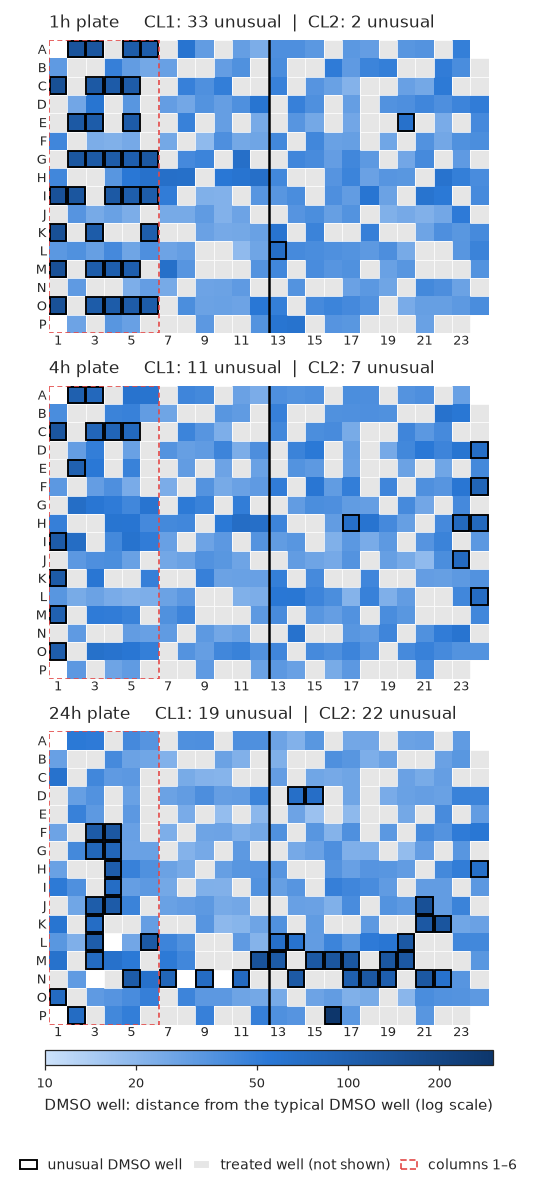

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(3.6, 7.4), layout="constrained")
norm = LogNorm(vmin=10, vmax=300)
cmap = blues.copy()
cmap.set_bad("white")
for ax, time in zip(axes, plate_order):
    plate = wells.filter(pl.col("time_point") == time)
    grid = np.full((16, 24), np.nan)
    dmso = plate.filter(pl.col("is_dmso"))
    grid[dmso["row_idx"].to_numpy(), dmso["col_idx"].to_numpy()] = dmso["distance"].to_numpy()
    image = ax.imshow(grid, cmap=cmap, norm=norm, aspect="equal", interpolation="none")
    # treated wells: light grey squares
    treated = plate.filter(~pl.col("is_dmso"))
    for r, c in zip(treated["row_idx"], treated["col_idx"]):
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=background, edgecolor="white", lw=0.3))
    for r, c in plate.filter(pl.col("unusual_dmso")).select("row_idx", "col_idx").iter_rows():
        ax.add_patch(Rectangle((c - 0.45, r - 0.45), 0.9, 0.9, fill=False, edgecolor="black", lw=0.9))
    # the plate area of panel c of the DMSO UMAP
    ax.add_patch(Rectangle((-0.5, -0.5), 6, 16, fill=False, edgecolor="#e34948", lw=0.8, ls=(0, (3, 2))))
    ax.axvline(11.5, color="black", lw=1.2)
    ax.set_xticks(range(24), [str(c) if c % 2 == 1 else "" for c in range(1, 25)])
    ax.set_yticks(range(16), plate_rows)
    ax.tick_params(length=0, pad=1)
    ax.spines[:].set_visible(False)
    n = {line: dmso_health.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))["unusual_wells"].item() for line in line_order}
    ax.set_title(f"{time} plate     CL1: {n['CL1']} unusual  |  CL2: {n['CL2']} unusual", loc="left")
cbar = fig.colorbar(image, ax=axes, location="bottom", shrink=0.85, aspect=30, pad=0.01)
cbar.set_ticks([10, 20, 50, 100, 200], labels=["10", "20", "50", "100", "200"])
cbar.minorticks_off()
cbar.set_label("DMSO well: distance from the typical DMSO well (log scale)")
fig.legend(
    handles=[
        Patch(facecolor="none", edgecolor="black", lw=0.9, label="unusual DMSO well"),
        Patch(facecolor=background, label="treated well (not shown)"),
        Patch(facecolor="none", edgecolor="#e34948", ls="--", lw=0.8, label="columns 1–6"),
    ],
    loc="lower center", bbox_to_anchor=(0.5, -0.06), ncols=3, handlelength=1.2, columnspacing=0.8,
)
save_fig(fig, "03_plate-maps_dmso-distance")

**Result:**

- **CL1 at 1h:** 33 of 127 DMSO wells are unusual, and all 33 lie in the odd rows of columns 1–6. The map shows stripes in every other row of the left part of the plate. Their cell number is close to normal (median 2,206 vs 2,375 cells), so this is not a density effect. At 4h, the same pattern is weaker: 11 unusual wells, all in the same area.
- **24h:** the unusual DMSO wells follow the low-count areas of notebook 02. In CL1 they sit in columns 3–4 and rows M–N (19 wells, median 1,110 vs 2,179 cells). In CL2 they sit in rows L–N (22 wells, median 3,070 vs 3,651 cells).
- **CL2 at 1h and 4h** is nearly clean: 2 and 7 unusual wells. At 4h, most of them sit at the right edge (columns 23–24).

## 8. Which technical factors explain the DMSO differences?

We test each factor on the DMSO wells of each plate and cell line. For three factors, we use rank (Spearman) correlations with the distance from DMSO, from −1 to 1:

| Factor | Measure | A technical effect looks like |
|---|---|---|
| Unusual cell number | \|log2(cells / DMSO median)\|: how far the count is from the median, in either direction | positive rho |
| Plate edge | wells between the well and the nearest edge | negative rho |
| Imaging order | minutes after the first well | positive rho (drift) |
| Plate area (CL1 only) | odd rows of columns 1–6 vs the other CL1 DMSO wells | larger distance in the area (Mann–Whitney test) |

This distance test can miss a smooth gradient across the plate. Section 8b adds a test for gradients.

**Pass if:** every correlation stays close to 0 (|rho| below about 0.3), and the plate area does not differ.

In [12]:
factor_rows = []
for (time, line), grp in wells.filter(pl.col("is_dmso")).group_by("time_point", "cell_line"):
    row = {
        "time_point": time, "cell_line": line, "dmso_wells": grp.height,
        "rho_unusual_cell_number": stats.spearmanr(grp["log2_cells"].abs(), grp["distance"]).statistic,
        "rho_wells_to_edge": stats.spearmanr(grp["wells_to_edge"], grp["distance"]).statistic,
        "rho_imaging_time": stats.spearmanr(grp["minutes_after_start"], grp["distance"]).statistic,
    }
    inside, outside = grp.filter(pl.col("shifted_area"))["distance"], grp.filter(~pl.col("shifted_area"))["distance"]
    if inside.len() >= 3:
        row["area_distance_ratio"] = inside.median() / outside.median()
        row["area_mannwhitney_p"] = stats.mannwhitneyu(inside, outside).pvalue
    factor_rows.append(row)
factors = pl.DataFrame(factor_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
factors.write_csv(table_dir / "dmso_technical-factors.csv")
factors.with_columns(pl.selectors.starts_with("rho", "area_distance").round(2))

time_point,cell_line,dmso_wells,rho_unusual_cell_number,rho_wells_to_edge,rho_imaging_time,area_distance_ratio,area_mannwhitney_p
str,str,i64,f64,f64,f64,f64,f64
"""1h""","""CL1""",127,0.32,-0.26,-0.14,3.72,1.5432e-17
"""1h""","""CL2""",127,0.3,-0.11,-0.04,null,null
"""4h""","""CL1""",127,0.51,-0.21,-0.15,1.93,6.2799e-15
"""4h""","""CL2""",127,0.57,-0.23,-0.07,null,null
"""24h""","""CL1""",125,0.66,-0.37,0.28,1.41,0.000294
"""24h""","""CL2""",127,0.6,0.02,0.41,null,null


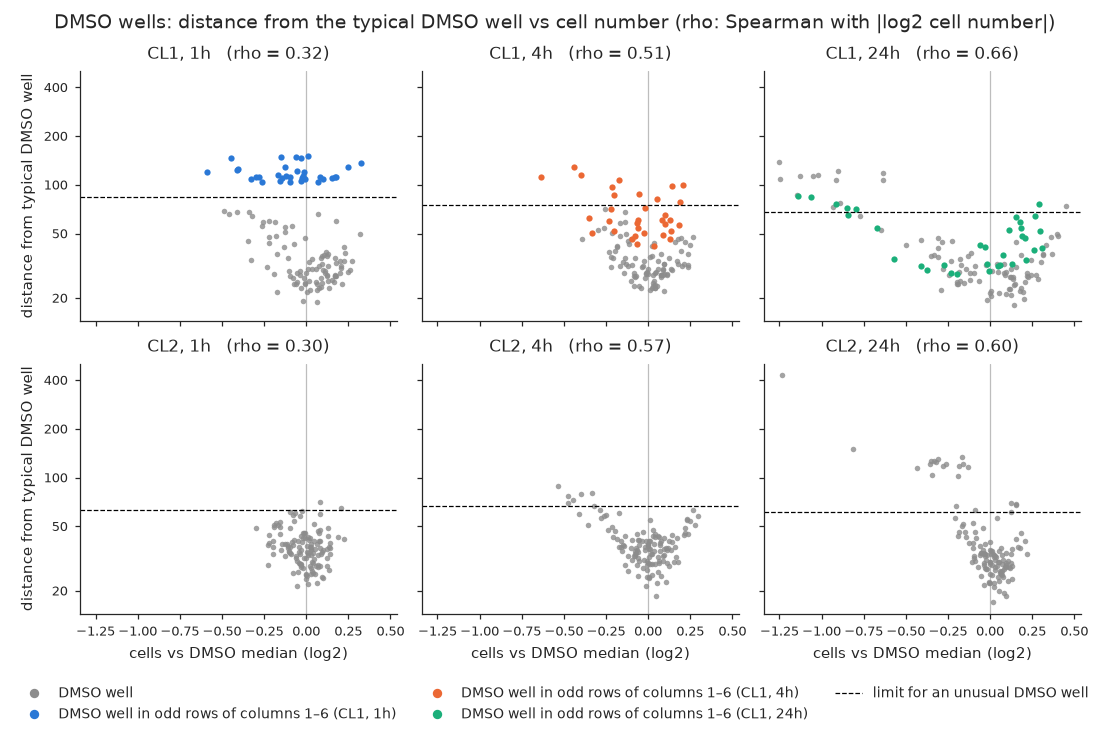

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.4), layout="constrained", sharex=True, sharey=True)
for i, line in enumerate(line_order):
    for j, time in enumerate(plate_order):
        ax = axes[i, j]
        grp = wells.filter(pl.col("is_dmso") & (pl.col("cell_line") == line) & (pl.col("time_point") == time))
        other, area = grp.filter(~pl.col("shifted_area")), grp.filter(pl.col("shifted_area"))
        ax.scatter(other["log2_cells"], other["distance"], s=7, color="#8c8c8c", alpha=0.8, linewidths=0, label="other DMSO wells")
        if area.height:
            ax.scatter(area["log2_cells"], area["distance"], s=9, color=plate_colors[time], linewidths=0, label="odd rows, columns 1–6")
        ax.axhline(grp["distance_limit"][0], color="black", lw=0.6, ls="--")
        ax.axvline(0, color="#bdbdbd", lw=0.6, zorder=0)
        rho = factors.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))["rho_unusual_cell_number"].item()
        ax.set_yscale("log")
        ax.set_yticks([20, 50, 100, 200, 400], ["20", "50", "100", "200", "400"])
        ax.minorticks_off()
        ax.set_title(f"{line}, {time}   (rho = {rho:.2f})")
for ax in axes[1]:
    ax.set_xlabel("cells vs DMSO median (log2)")
for ax in axes[:, 0]:
    ax.set_ylabel("distance from typical DMSO well")
fig.legend(
    handles=[Line2D([], [], marker="o", ls="", color="#8c8c8c", markersize=3.5, label="DMSO well"),
             *[Line2D([], [], marker="o", ls="", color=plate_colors[t], markersize=3.5, label=f"DMSO well in odd rows of columns 1–6 (CL1, {t})") for t in plate_order],
             Line2D([], [], color="black", lw=0.6, ls="--", label="limit for an unusual DMSO well")],
    loc="lower center", bbox_to_anchor=(0.5, -0.1), ncols=3,
)
fig.suptitle("DMSO wells: distance from the typical DMSO well vs cell number (rho: Spearman with |log2 cell number|)")
save_fig(fig, "04_dmso_distance-vs-cell-number")

**Result of the distance test: H0 rejected for plate area and cell number. The plate edge and the imaging order do not change the distance (section 8b finds a row gradient).**

- **Plate area:** in CL1, the DMSO wells in the odd rows of columns 1–6 lie further from the typical DMSO well than the other CL1 DMSO wells. They lie 3.7 times further at 1h (Mann–Whitney p = 2 × 10⁻¹⁷) and 1.9 times further at 4h (p = 6 × 10⁻¹⁵). At 24h the ratio is 1.4 (p = 0.0003). But this area overlaps the low-count block in columns 3–4, so the cause at 24h is not clear.
- A pattern in every other row points to liquid handling (for example one channel of a multichannel dispenser), not to biology. The records do not show which step caused it.
- **Cell number:** DMSO wells whose cell number is further from the median differ more, on every plate. rho is 0.30–0.32 at 1h, 0.51–0.57 at 4h and 0.60–0.66 at 24h. The scatter plots have a V shape: wells with fewer cells and wells with more cells both differ. At 24h, all DMSO wells far beyond the limit have fewer cells.
- **Plate edge:** rho is −0.26 to 0.02, except for CL1 at 24h (−0.37). On that plate, the low-count block lies inside the plate, so edge wells have more cells (notebook 02). This is the cell number effect, not an edge effect.
- **Imaging order:** rho is −0.15 to −0.04 at 1h and 4h. So DMSO wells imaged later are not *further* from the typical DMSO well. At 24h, rho is 0.28 (CL1) and 0.41 (CL2), but the rows imaged last (M–N) are also the low-count rows.
- A gradient can move wells in one direction at the top of the plate and in the other direction at the bottom. This test cannot find such a gradient. Section 8b tests for it.

### 8b. Gradients across the plate

The distance test above only finds DMSO wells that sit *far* from the typical DMSO well. A smooth gradient puts wells on both sides of the centre. For example, the top rows move to one side and the bottom rows to the other side. Their distance hardly changes, so the distance test misses the gradient.

To find gradients, we use the main directions in which the DMSO wells differ:

1. For each plate and cell line, we run a PCA on the rescaled DMSO wells, and keep the top 5 principal components (PCs).
2. We correlate each factor with each PC (Spearman rho).
3. For each factor, we report the PC that it follows most, and the share of the DMSO variation that this PC carries.

The microscope imaged the plate row by row, so the row and the imaging time are one factor here. The data cannot separate them.

**Pass if:** no factor follows a PC with |rho| ≥ 0.5.

In [14]:
gradient_factors = {"row (= imaging order)": "row_idx", "column": "col_idx", "wells to the edge": "wells_to_edge", "cell number": "log2_cells"}
gradient_rows = []
for line in line_order:
    for time in plate_order:
        grp = wells.filter(pl.col("is_dmso") & (pl.col("cell_line") == line) & (pl.col("time_point") == time))
        pca = PCA(n_components=5, random_state=seed).fit(profiles[grp["row"].to_numpy()])
        pcs = pca.transform(profiles[grp["row"].to_numpy()])
        for name, column in gradient_factors.items():
            rhos = np.array([stats.spearmanr(grp[column], pcs[:, k]).statistic for k in range(5)])
            k = int(np.argmax(np.abs(rhos)))
            gradient_rows.append({
                "cell_line": line, "time_point": time, "factor": name, "pc": f"PC{k + 1}",
                "pct_variance_of_pc": 100 * pca.explained_variance_ratio_[k], "rho": rhos[k],
            })
gradients = pl.DataFrame(gradient_rows)
gradients.write_csv(table_dir / "dmso_gradients.csv")
gradients.with_columns(pl.col("pct_variance_of_pc").round(1), pl.col("rho").round(2))

cell_line,time_point,factor,pc,pct_variance_of_pc,rho
str,str,str,str,f64,f64
"""CL1""","""1h""","""row (= imaging order)""","""PC4""",3.4,-0.72
"""CL1""","""1h""","""column""","""PC1""",68.5,-0.3
"""CL1""","""1h""","""wells to the edge""","""PC2""",11.6,-0.4
"""CL1""","""1h""","""cell number""","""PC2""",11.6,0.82
"""CL1""","""4h""","""row (= imaging order)""","""PC4""",4.6,0.64
"""CL1""","""4h""","""column""","""PC1""",45.6,-0.35
"""CL1""","""4h""","""wells to the edge""","""PC1""",45.6,-0.5
"""CL1""","""4h""","""cell number""","""PC2""",18.7,-0.88
"""CL1""","""24h""","""row (= imaging order)""","""PC4""",2.9,-0.48


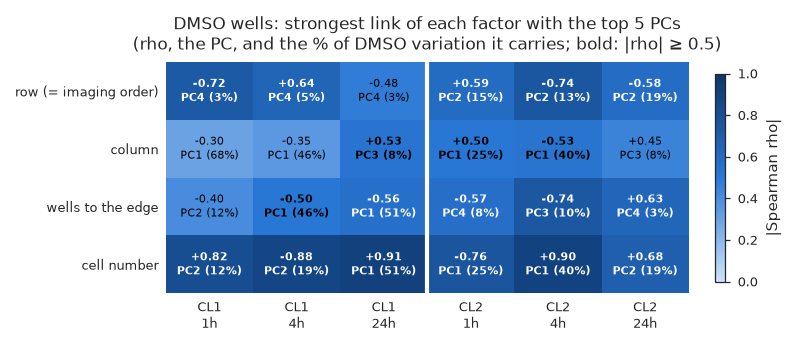

In [15]:
panels = [(line, time) for line in line_order for time in plate_order]
names = list(gradient_factors)
lookup = {(r["factor"], r["cell_line"], r["time_point"]): r for r in gradients.iter_rows(named=True)}
matrix = np.array([[abs(lookup[(n, l, t)]["rho"]) for l, t in panels] for n in names])
fig, ax = plt.subplots(figsize=(5.2, 2.2), layout="constrained")
image = ax.imshow(matrix, cmap=blues, vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(matrix):
    hit = lookup[(names[r], *panels[c])]
    ax.text(c, r, f"{hit['rho']:+.2f}\n{hit['pc']} ({hit['pct_variance_of_pc']:.0f}%)", ha="center", va="center", fontsize=5.5,
            color="white" if v > 0.55 else "black", fontweight="bold" if v >= 0.5 else "normal")
ax.set_xticks(range(len(panels)), [f"{l}\n{t}" for l, t in panels])
ax.set_yticks(range(len(names)), names)
ax.axvline(2.5, color="white", lw=2)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.colorbar(image, ax=ax, shrink=0.9, label="|Spearman rho|")
ax.set_title("DMSO wells: strongest link of each factor with the top 5 PCs\n(rho, the PC, and the % of DMSO variation it carries; bold: |rho| ≥ 0.5)")
save_fig(fig, "04b_dmso_gradients")

**Result of 8b: H0 rejected for cell number and for the row (= imaging order). The edge and the column have weaker links.**

- **Cell number** is the strongest gradient. It follows a large PC in every panel (|rho| 0.68–0.91, and the PC carries 12–51% of the DMSO variation). In 4 of the 6 panels, it is PC1 or PC2.
- **Row (= imaging order)** follows a PC in every panel. In CL2 it is a medium PC (|rho| 0.58–0.74, PC2, 13–19% of the variation). In CL1 it is a small PC (|rho| 0.48–0.72, PC4, 3–5%). So the DMSO profiles drift from the top rows to the bottom rows of the plate.
- The microscope imaged the plate row by row. So the drift can be a position effect or a drift during the 3.8 hours of imaging. A position effect can come from liquid handling or temperature across the plate, for example. The data cannot tell the two apart.
- **Edge and column:** most of their strong links share a PC with cell number or with the odd-row area. For example, in CL1 at 1h, PC1 (69% of the variation) is the shifted area. On their own, the edge and the column follow only small PCs (3–10% of the variation). For example, the edge in CL2 at 4h has rho −0.74 with PC3 (10%).
- The UMAP of section 6 shows the same patterns: the imaging-time gradient in panel f, and the low-count wells in panel d.

## 9. How many features follow cell number?

For each plate and cell line, we compute the Spearman correlation of every feature with the cell number (log2 ratio) across the DMSO wells. A feature **follows cell number** when |rho| ≥ 0.5. Without any treatment, such a link can only come from density, or from the cause of the density difference (seeding, handling).

**Pass if:** under about 10% of features follow cell number.

In [16]:
groups = [(line, time) for line in line_order for time in plate_order]
categories = [name.split("_")[1] for name in agg_profiles.var_names]
category_order = [c for c, _ in pl.Series(categories).value_counts(sort=True).iter_rows()]
rho_rows = []
for line, time in groups:
    grp = wells.filter(pl.col("is_dmso") & (pl.col("cell_line") == line) & (pl.col("time_point") == time))
    rho = stats.spearmanr(grp["log2_cells"].to_numpy(), profiles[grp["row"].to_numpy()], axis=0).statistic[0, 1:]
    rho_rows.append(pl.DataFrame({"feature": agg_profiles.var_names.to_list(), "category": categories, "rho": rho}).with_columns(
        cell_line=pl.lit(line), time_point=pl.lit(time)))
rho_table = pl.concat(rho_rows)
rho_table.write_csv(table_dir / "dmso_feature-vs-cell-number_spearman.csv")

follow = (
    pl.concat([rho_table, rho_table.with_columns(category=pl.lit("All features"))])
    .group_by("category", "cell_line", "time_point")
    .agg(n=pl.len(), pct=(100 * (pl.col("rho").abs() >= strong_rho).mean()))
)
summary = follow.filter(pl.col("category") == "All features").sort("cell_line", pl.col("time_point").cast(pl.Enum(plate_order)))
summary.select("cell_line", "time_point", "n", pl.col("pct").round(1)).join(
    rho_table.sort(pl.col("rho").abs(), descending=True).group_by("cell_line", "time_point", maintain_order=True)
    .agg(top_feature=pl.col("feature").first(), top_rho=pl.col("rho").first().round(2)),
    on=["cell_line", "time_point"], maintain_order="left",
)

cell_line,time_point,n,pct,top_feature,top_rho
str,str,u32,f64,str,f64
"""CL1""","""1h""",1399,23.4,"""Nuclei_Intensity_StdIntensity_CorrER""",-0.88
"""CL1""","""4h""",1399,30.9,"""Cells_Correlation_RWC_CorrDNA_CorrER""",-0.89
"""CL1""","""24h""",1399,58.5,"""Nuclei_Texture_InfoMeas2_CorrER_5_00_256""",-0.96
"""CL2""","""1h""",1399,25.2,"""Cells_Correlation_RWC_CorrDNA_CorrER""",-0.85
"""CL2""","""4h""",1399,50.5,"""Cells_Correlation_RWC_CorrDNA_CorrAGP""",-0.93
"""CL2""","""24h""",1399,35.2,"""Cells_Neighbors_SecondClosestDistance_Adjacent""",-0.96


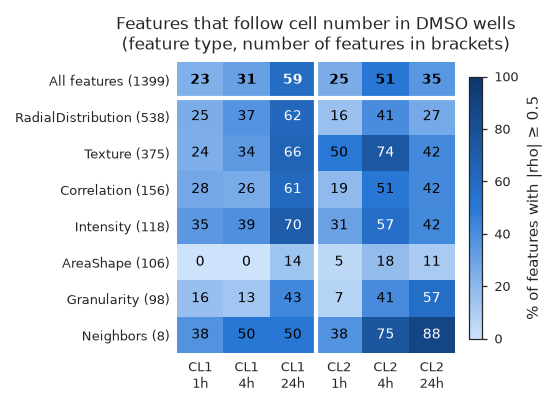

In [17]:
row_names = ["All features", *category_order]
matrix = np.array([[follow.filter((pl.col("category") == c) & (pl.col("cell_line") == l) & (pl.col("time_point") == t))["pct"].item()
                    for l, t in groups] for c in row_names])
n_features = {c: follow.filter((pl.col("category") == c))["n"][0] for c in row_names}
fig, ax = plt.subplots(figsize=(3.6, 2.6), layout="constrained")
image = ax.imshow(matrix, cmap=blues, vmin=0, vmax=100, aspect="auto")
for (r, c), v in np.ndenumerate(matrix):
    ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 55 else "black",
            fontweight="bold" if r == 0 else "normal")
ax.set_xticks(range(len(groups)), [f"{l}\n{t}" for l, t in groups])
ax.set_yticks(range(len(row_names)), [f"{c} ({n_features[c]})" for c in row_names])
ax.axhline(0.5, color="white", lw=2)
ax.axvline(2.5, color="white", lw=2)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.colorbar(image, ax=ax, shrink=0.9, label=f"% of features with |rho| ≥ {strong_rho}")
ax.set_title("Features that follow cell number in DMSO wells\n(feature type, number of features in brackets)")
save_fig(fig, "05_dmso_features-following-cell-number")

**Result: FAIL on every plate.**

- 23–59% of the 1,399 features follow cell number in DMSO wells (pass: below 10%). The share is highest for CL1 at 24h (59%), where cell numbers vary most, and for CL2 at 4h (51%).
- Neighbor features (how crowded a cell is) follow cell number most (38–88% of 8 features). Texture, intensity and correlation features come next. Cell and nucleus shape (AreaShape) follow it least (0–18%).
- The top features reach |rho| 0.85–0.96, for example `Nuclei_Texture_InfoMeas2_CorrER_5_00_256` and `Cells_Correlation_RWC_CorrDNA_CorrER`.
- So a treatment that changes the cell number also changes many features through density alone. Notebook 04 checks this for the treatments that lower the cell number.

## 10. Save the results

We save the UMAP coordinates of the three maps (with metadata) and the distance of every well from DMSO. Other notebooks can then use them without running this one.

In [18]:
for adata, name in [(sc_sample, "qced_sc-sample"), (agg_profiles, "qced_wells"), (dmso_adata, "qced_dmso-wells")]:
    metadata_columns = [column for column in adata.obs.columns if column.startswith("Metadata_")]
    table = pl.from_pandas(adata.obs[metadata_columns].astype(str).reset_index(drop=True)).with_columns(
        pl.Series("UMAP1", adata.obsm["X_umap"][:, 0]), pl.Series("UMAP2", adata.obsm["X_umap"][:, 1])
    )
    table.write_parquet(results_dir / f"umap_{name}.parquet")
    print(f"umap_{name}.parquet: {table.height:,} rows")
wells.select(
    "Metadata_Plate", "Metadata_Well", "time_point", "cell_line", "Metadata_Perturbation", "is_dmso", "n_cells_all", "log2_cells",
    "shifted_area", "wells_to_edge", "minutes_after_start", "distance", "distance_limit", "unusual_dmso",
).write_csv(table_dir / "well_distance-and-technical-factors.csv")

umap_qced_sc-sample.parquet: 113,600 rows
umap_qced_wells.parquet: 1,136 rows
umap_qced_dmso-wells.parquet: 760 rows


## Summary

**Question:** what drives the differences between the profiles: biology or technical effects?

**Biology:** cell line and time point drive the largest differences between single cells. Among the treatments, CBK600005 stands apart from DMSO. The other treatments mostly mix with DMSO.

**Batch effects in the DMSO wells (H0 rejected):**

| Batch effect | Where | Evidence | What to do |
|---|---|---|---|
| **Plate area** | CL1, odd rows of columns 1–6, at 1h (strong) and 4h (weaker) | 33 (1h) and 11 (4h) of 127 DMSO wells are unusual, all in this area. They are 3.7× and 1.9× further from the typical DMSO well, and form their own UMAP island. | Flag treated wells in this area (notebook 03 marks them †). Check the liquid handling of these rows. |
| **Cell number** | every plate, strongest at 24h | DMSO distance follows cell number (rho 0.30–0.66). 23–59% of features follow cell number. | Compare wells with DMSO wells of similar cell number, or correct for cell number. Read the profiles of treatments that lower cell number with care (notebook 04). |
| **Low-count areas** | 24h plate: CL1 columns 3–4 and rows M–N, CL2 rows L–N | 19 (CL1) and 22 (CL2) unusual DMSO wells with fewer cells | A seeding or handling problem (notebook 02). It is part of the cell number effect. |
| **Row gradient (= imaging order)** | every plate, clearest in CL2 | A PC of the DMSO wells follows the row: \|rho\| 0.58–0.74 and 13–19% of the DMSO variation in CL2, 3–5% in CL1. | Randomize the layout, so treatments are not tied to rows. Put DMSO wells in every row. Consider a row-wise correction. |

**Weak or no batch effects:** the plate edge and the column have little effect on their own. They follow only small PCs (3–10% of the DMSO variation), or they share a PC with cell number. The plates as a whole do not differ, because each plate is normalized to its own DMSO cells.

**Not testable with this design:** time point and imaging settings change together (the 24h plate used longer ER and AGP exposures). Cell line and plate half also change together (CL1 always in columns 1–12). So we make all comparisons within one plate and cell line.

**Output:**

- UMAP coordinates in `results/umap_qced_*.parquet` (single cells, all wells, DMSO wells).
- The distance from DMSO and the technical factors of every well in `results/tables/01.batch-effects-diagnosis/well_distance-and-technical-factors.csv`.
- The gradient test in `dmso_gradients.csv`.
- Figures in `results/figures/01.batch-effects-diagnosis/`.